<a href="https://colab.research.google.com/github/tbruffy/financial-economics-ps3/blob/main/ps3_q4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Financial Economics I — Problem Set 3, Question 4

## Part (a): Numerical solution and policy functions

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

# Preferences and horizon
gamma = 5.0
beta = 0.95
T = 5

# Returns
r = 0.015       # Net riskless return
mu = 0.065      # Expected risky excess return
sig = 0.18      # Std dev of risky returns

Rf = 1.0 + r

In [15]:
# Wealth grid: 50 equally spaced points in log wealth
minw = np.log(1.0)
maxw = np.log(50.0)
nw = 50

gw = np.linspace(minw, maxw, nw)
egw = np.exp(gw)

# Number of candidates at each wealth level
nc = 25

# Portfolio grid: 21 risky shares in [0, 1], including both endpoints
na = 21
ga = np.linspace(0.0, 1.0, na)

# Solution arrays: rows = wealth levels, columns = decision periods
c = np.zeros((nw, T))
v = np.zeros((nw, T))
a = np.full((nw, T), np.nan)

In [16]:
# Three-point Gaussian quadrature (normally distributed returns)
nqp = 3

# Standard normal nodes
normal_nodes = np.array([-np.sqrt(3.0), 0.0, np.sqrt(3.0)])

# Gross risky return nodes: mean = 1 + r + mu = 1.08
gret = (1.0 + r + mu) + sig * normal_nodes

# Quadrature weights
weight = np.array([1.0 / 6.0, 2.0 / 3.0, 1.0 / 6.0])

# Quadrature distribution
quad_mean = np.sum(weight * gret)
quad_var = np.sum(weight * (gret - quad_mean)**2)

print("Gross return nodes:", gret)
print("Weights:", weight)
print("Sum of weights:", weight.sum())
print("Mean:", quad_mean)
print("Variance:", quad_var)

Gross return nodes: [0.76823085 1.08       1.39176915]
Weights: [0.16666667 0.66666667 0.16666667]
Sum of weights: 0.9999999999999999
Mean: 1.0799999999999998
Variance: 0.032399999999999984


In [17]:
# Terminal period: t = 5 corresponds to Python column T - 1
c[:, T - 1] = egw

v[:, T - 1] = (
    c[:, T - 1] ** (1.0 - gamma) / (1.0 - gamma)
)

# No savings in the terminal period (Portfolio choice is irrelevant)
a[:, T - 1] = np.nan

# Terminal solution at the lowest wealth-grid point
print("Terminal wealth:", egw[0])
print("Terminal consumption:", c[0, T - 1])
print("Terminal value:", v[0, T - 1])

Terminal wealth: 1.0
Terminal consumption: 1.0
Terminal value: -0.25


In [18]:
# Backward induction: periods 4, 3, 2, 1
for i in range(T - 2, -1, -1):

    # Next-period value as a function of log wealth
    spline_v = CubicSpline(gw, v[:, i + 1])

    # Loop over current wealth levels
    for z in range(nw):
        W = egw[z]

        # Consumption grid: same convention as the lecture example
        gc = np.linspace(0.001, 0.999 * c[z, i + 1], nc)

        # Candidate values: rows = consumption, columns = risky share
        auxV = np.full((nc, na), -np.inf)

        for j in range(nc):
            C = gc[j]
            sav = W - C

            for k in range(na):
                alpha = ga[k]

                # Gross portfolio return at each quadrature node
                portfolio_return = alpha * gret + (1.0 - alpha) * Rf

                # Next-period wealth at each quadrature node
                W_next = portfolio_return * sav

                # Evaluate the spline within the wealth-grid boundaries
                W_eval = np.clip(W_next, egw[0], egw[-1])
                V_next = spline_v(np.log(W_eval))

                # Outside the grid, use CRRA homogeneity
                V_next = V_next * (
                    W_next / W_eval
                ) ** (1.0 - gamma)

                # Quadrature approximation to expected continuation value
                expected_V = np.sum(weight * V_next)

                # Current utility plus discounted continuation value
                auxV[j, k] = (
                    C ** (1.0 - gamma) / (1.0 - gamma)
                    + beta * expected_V
                )

        # Locate the best consumption–portfolio pair
        j_best, k_best = np.unravel_index(
            np.argmax(auxV), auxV.shape
        )

        # Store the optimal value and decisions
        v[z, i] = auxV[j_best, k_best]
        c[z, i] = gc[j_best]
        a[z, i] = ga[k_best]

    print(f"Solved period {i + 1}")

Solved period 4
Solved period 3
Solved period 2
Solved period 1


In [19]:
# Check that consumption and value are finite
assert np.all(np.isfinite(c)), "Non-finite consumption found."
assert np.all(np.isfinite(v)), "Non-finite value found."

# Check consumption feasibility at every wealth level and date
assert np.all(c > 0.0), "Consumption must be positive."
assert np.all(c <= egw[:, None] + 1e-10), "Consumption exceeds wealth."

# Check portfolio choices in periods with positive savings
assert np.all(np.isfinite(a[:, :-1])), "Missing portfolio choices."
assert np.all((a[:, :-1] >= 0.0) & (a[:, :-1] <= 1.0)), \
    "Portfolio shares must lie between 0 and 1."

# Check the terminal-period solution
assert np.allclose(c[:, -1], egw), \
    "Terminal consumption should equal wealth."
assert np.all(np.isnan(a[:, -1])), \
    "Terminal portfolio choice should remain undefined."

print("All feasibility checks passed.")

All feasibility checks passed.


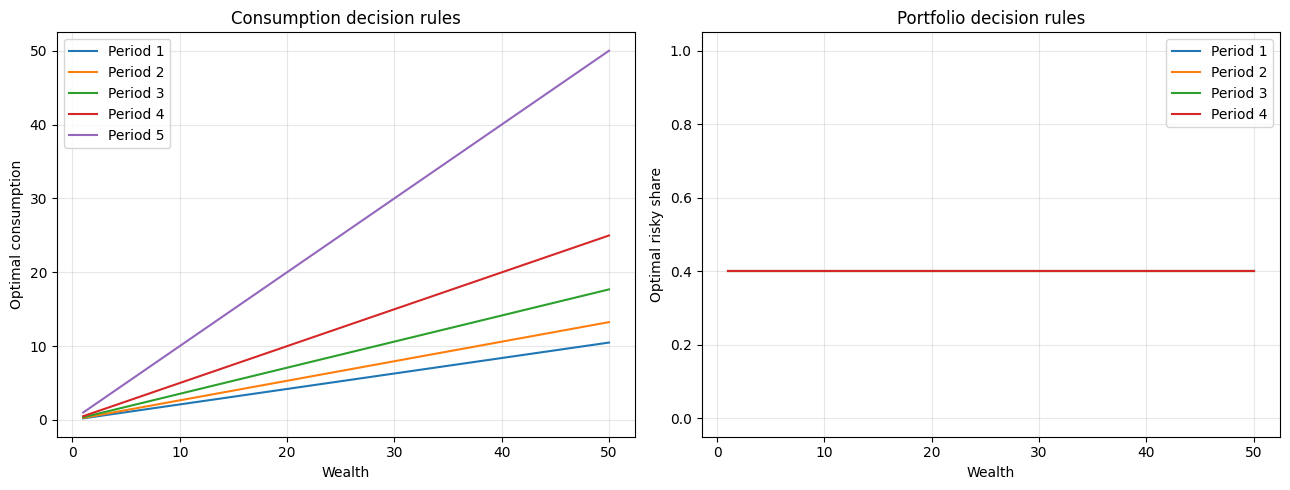

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Consumption policies: periods 1–5
for i in range(T):
    axes[0].plot(egw, c[:, i], label=f"Period {i + 1}")

axes[0].set_xlabel("Wealth")
axes[0].set_ylabel("Optimal consumption")
axes[0].set_title("Consumption decision rules")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Portfolio policies: periods 1–4
for i in range(T - 1):
    axes[1].plot(egw, a[:, i], label=f"Period {i + 1}")

axes[1].set_xlabel("Wealth")
axes[1].set_ylabel("Optimal risky share")
axes[1].set_title("Portfolio decision rules")
axes[1].set_ylim(-0.05, 1.05)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("ps3_q4a_policy_functions.png", dpi=300, bbox_inches="tight")
plt.show()

## Part (b): Simulation of 10,000 investors

All investors begin with wealth 10 and follow the optimal policies
computed in Part (a). Returns are drawn independently across investors
and periods. A fixed random seed ensures reproducibility.

We report average consumption, wealth before consumption, and risky
portfolio share for each decision period.

In [21]:
# Simulation settings
nsim = 10_000
W_initial = 10.0

# Fixed seed
rng = np.random.default_rng(12345)

# Independent gross risky returns for each investor and period
R_sim = rng.normal(
    loc=1.0 + r + mu,
    scale=sig,
    size=(nsim, T)
)

# Rows = investors; columns = decision periods 1–5
W_sim = np.zeros((nsim, T))
C_sim = np.zeros((nsim, T))
A_sim = np.full((nsim, T), np.nan)

# Everyone enters the first decision period with wealth 10
W_sim[:, 0] = W_initial

print("Return array shape:", R_sim.shape)
print("Mean simulated risky return:", R_sim.mean())
print("Standard deviation:", R_sim.std())
print("Initial wealth:", W_sim[0, 0])

Return array shape: (10000, 5)
Mean simulated risky return: 1.0806550627689608
Standard deviation: 0.17934333390032717
Initial wealth: 10.0


In [22]:
# Five decision periods
for i in range(T):
    W_current = W_sim[:, i]

    # Wealth must be positive (CRRA + log interpolation)
    assert np.all(np.isfinite(W_current))
    assert np.all(W_current > 0.0)

    # Terminal period: consume everything; no portfolio decision
    if i == T - 1:
        C_sim[:, i] = W_current
        A_sim[:, i] = np.nan
        continue

    # Interpolate policies in log wealth
    logW = np.log(W_current)

    consumption_ratio = np.interp(
        logW,
        gw,
        c[:, i] / egw
    )

    alpha = np.interp(
        logW,
        gw,
        a[:, i]
    )

    # Apply to each investor
    C_sim[:, i] = consumption_ratio * W_current
    A_sim[:, i] = alpha

    # Savings earn the realized gross portfolio return
    savings = W_current - C_sim[:, i]

    portfolio_return = (
        alpha * R_sim[:, i]
        + (1.0 - alpha) * Rf
    )

    assert np.all(portfolio_return > 0.0), \
        "A simulated portfolio return is nonpositive."

    # Wealth entering the next decision period
    W_sim[:, i + 1] = savings * portfolio_return

print("Simulation complete.")

Simulation complete.


In [23]:
# Wealth and consumption must be finite and positive
assert np.all(np.isfinite(W_sim))
assert np.all(np.isfinite(C_sim))
assert np.all(W_sim > 0.0)
assert np.all(C_sim > 0.0)

# Consumption cannot exceed available wealth
assert np.all(C_sim <= W_sim + 1e-10)

# Everyone begins with wealth 10
assert np.allclose(W_sim[:, 0], W_initial)

# Portfolio shares must be valid in periods 1–4
assert np.all(np.isfinite(A_sim[:, :-1]))
assert np.all(
    (A_sim[:, :-1] >= 0.0) & (A_sim[:, :-1] <= 1.0)
)

# Terminal consumption exhausts wealth
assert np.allclose(C_sim[:, -1], W_sim[:, -1])
assert np.all(np.isnan(A_sim[:, -1]))

# Verify the wealth transitions (periods 1–4)
implied_next_wealth = (
    A_sim[:, :-1] * R_sim[:, :-1]
    + (1.0 - A_sim[:, :-1]) * Rf
) * (W_sim[:, :-1] - C_sim[:, :-1])

assert np.allclose(W_sim[:, 1:], implied_next_wealth)

print("All simulation checks passed.")

All simulation checks passed.


In [24]:
# Average across investors, separately for each period
mean_W = W_sim.mean(axis=0)
mean_C = C_sim.mean(axis=0)

# Portfolio shares are defined only in periods 1–4
mean_A = np.full(T, np.nan)
mean_A[:-1] = A_sim[:, :-1].mean(axis=0)

# Print a results table
print(
    f"{'Period':>6} "
    f"{'Mean wealth':>14} "
    f"{'Mean consumption':>18} "
    f"{'Mean risky share':>18}"
)

for i in range(T):
    risky_share = (
        f"{mean_A[i]:.4f}" if i < T - 1 else "N/A"
    )

    print(
        f"{i + 1:>6} "
        f"{mean_W[i]:>14.4f} "
        f"{mean_C[i]:>18.4f} "
        f"{risky_share:>18}"
    )

Period    Mean wealth   Mean consumption   Mean risky share
     1        10.0000             2.0953             0.4000
     2         8.2261             2.1792             0.4000
     3         6.2988             2.2270             0.4000
     4         4.2386             2.1177             0.4000
     5         2.2079             2.2079                N/A


### Simulation results

I simulated 10,000 investors, each beginning with wealth 10 and
following the policies computed in Part (a). Gross risky returns
were drawn independently from N(1.08, 0.18²), using random seed 12345.

The table reports average wealth before consumption, average
consumption, and the average individual risky portfolio share
in each period.

The risky share is 40% in periods 1–4. In period 5, investors consume
all remaining wealth, so the portfolio share is undefined (N/A).